In [1]:

import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os 
import sys


# Exploratory Data Analysis (EDA)

In [2]:
#Load dataset
data_path = '../data/diabetes_prediction_dataset.csv'
if not os.path.exists(data_path):
    print(f"❌ Error: Data file not found at {data_path}")
    sys.exit(1)

df = pd.read_csv(data_path)

print(f"  ✅ Loaded: {data_path}")
print(f"  📈 Shape: {df.shape[0]:,} rows × {df.shape[1]} columns\n")

  ✅ Loaded: ../data/diabetes_prediction_dataset.csv
  📈 Shape: 100,000 rows × 9 columns



In [3]:
df.sample(10)

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
79209,Female,41.0,0,0,No Info,21.00,4.5,145,0
9137,Female,20.0,0,0,No Info,23.87,4.0,159,0
56621,Female,62.0,0,0,No Info,27.17,3.5,200,0
83059,Male,16.0,0,0,No Info,27.19,4.5,90,0
39532,Female,64.0,0,0,No Info,27.32,6.0,85,0
4235,Female,33.0,0,0,never,35.48,6.1,100,0
68585,Male,59.0,0,1,No Info,27.32,5.0,140,0
98194,Female,66.0,0,0,No Info,27.32,5.8,80,0
57996,Female,11.0,0,0,No Info,14.09,5.7,160,0
47127,Male,51.0,0,0,No Info,29.87,4.0,200,0


In [4]:
#Missing values
df.isnull().sum()

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

In [5]:
df.dtypes

gender                     str
age                    float64
hypertension             int64
heart_disease            int64
smoking_history            str
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes                 int64
dtype: object

In [6]:
df.describe().round(3)

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000.000,100000.000,100000.000,100000.000,100000.000,100000.000,100000.000
mean,41.886,0.075,0.039,27.321,5.528,138.058,0.085
std,22.517,0.263,0.195,6.637,1.071,40.708,0.279
min,0.080,0.000,0.000,10.010,3.500,80.000,0.000
25%,24.000,0.000,0.000,23.630,4.800,100.000,0.000
50%,43.000,0.000,0.000,27.320,5.800,140.000,0.000
75%,60.000,0.000,0.000,29.580,6.200,159.000,0.000
max,80.000,1.000,1.000,95.690,9.000,300.000,1.000


In [7]:
#Split the dataset's columns in numerical and categorical columns
numerical = ['bmi', 'age', 'blood_glucose_level','HbA1c_level']
categorical = ['gender', 'hypertension', 'heart_disease', 'smoking_history']

In [8]:
df[categorical].nunique()

gender             3
hypertension       2
heart_disease      2
smoking_history    6
dtype: int64

In [9]:

df.gender.unique()

<StringArray>
['Female', 'Male', 'Other']
Length: 3, dtype: str

In [10]:

df.gender.value_counts()

gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64

# Distribution 

In [11]:
#Target
df['diabetes'].value_counts()

diabetes
0    91500
1     8500
Name: count, dtype: int64

In [12]:
#Categorical variables
df['hypertension'].value_counts()

hypertension
0    92515
1     7485
Name: count, dtype: int64

In [13]:
df['heart_disease'].value_counts()

heart_disease
0    96058
1     3942
Name: count, dtype: int64

In [14]:
df['smoking_history'].value_counts()

smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64

In [15]:
#Distribution of numerical variables
def rango(df):
    return max(df) - min(df)
df[numerical].agg(['max','min',rango,'mean','median','std'])

,bmi,age,blood_glucose_level,HbA1c_level
max,95.690000,80.000000,300.000000,9.000000
min,10.010000,0.080000,80.000000,3.500000
rango,85.680000,79.920000,220.000000,5.500000
mean,27.320767,41.885856,138.058060,5.527507
median,27.320000,43.000000,140.000000,5.800000
std,6.636783,22.516840,40.708136,1.070672


In [16]:
df[numerical].mode()

,bmi,age,blood_glucose_level,HbA1c_level
0,27.32,80.0,130,6.6


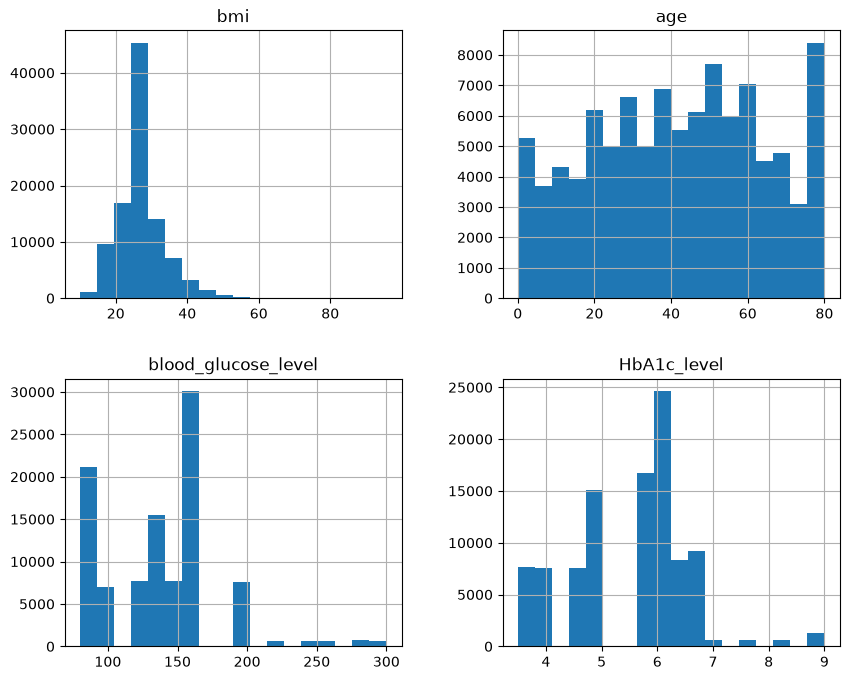

In [17]:
df[numerical].hist(figsize=(10, 8), bins=18)
plt.show()

In [18]:
"""Duplicated data : Remove exact duplicate rows as repeated records; 
the dataset has no patient identifier to establish whether all such rows are the same person
"""
df.duplicated().sum()

np.int64(3854)

In [19]:
df_duplicados = df[df.duplicated(keep=False)]
df_duplicados.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
10,Female,53.0,0,0,never,27.32,6.1,85,0
14,Female,76.0,0,0,No Info,27.32,5.0,160,0
18,Female,42.0,0,0,No Info,27.32,5.7,80,0
41,Male,5.0,0,0,No Info,27.32,6.6,130,0


In [20]:
#remove duplicated
df.drop_duplicates(inplace=True)

In [21]:
df[numerical].agg(['max','min',rango,'mean','median','std'])

,bmi,age,blood_glucose_level,HbA1c_level
max,95.690000,80.000000,300.000000,9.000000
min,10.010000,0.080000,80.000000,3.500000
rango,85.680000,79.920000,220.000000,5.500000
mean,27.321461,41.794326,138.218231,5.532609
median,27.320000,43.000000,140.000000,5.800000
std,6.767716,22.462948,40.909771,1.073232


In [22]:
df[numerical].mode()

,bmi,age,blood_glucose_level,HbA1c_level
0,27.32,80.0,159,6.6


In [23]:
#Distribution after remove duplicated
df['diabetes'].value_counts(normalize=True)

diabetes
0    0.91178
1    0.08822
Name: proportion, dtype: float64

In [24]:
df['gender'].value_counts()

gender
Female    56161
Male      39967
Other        18
Name: count, dtype: int64

In [25]:
df[df['gender']=='Other']

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
12669,Other,10.0,0,0,not current,14.09,5.0,140,0
14838,Other,19.0,0,0,No Info,27.32,5.7,158,0
16702,Other,39.0,0,0,not current,31.24,6.2,85,0
18691,Other,10.0,0,0,not current,16.59,6.1,160,0
23266,Other,23.0,0,0,No Info,24.23,6.1,140,0
31985,Other,53.0,0,0,No Info,27.32,6.6,160,0
33805,Other,45.0,0,0,never,27.32,4.0,159,0
34929,Other,47.0,0,0,never,36.76,6.6,90,0
35006,Other,47.0,0,0,never,36.76,3.5,200,0
40337,Other,18.0,0,0,not current,30.19,6.1,90,0


It was decided to retain the 'other' category within the gender variable to preserve the integrity of the dataset and avoid selection bias

In [26]:
df.to_csv('../data/diabetes_prediction_dataset_cleaned_v2.csv', index=False)